# Mini-TP 5 — Federa tu modelo y mide el trade-off (Sesión 5)

Federo **mi modelo** (`iris-rf`, el mismo servido por REST en el Mini-TP 1,
descripto por GraphQL en el Mini-TP 2, expuesto por gRPC en el Mini-TP 3 y
puntuado en streaming en el Mini-TP 4) y mido cuánto cuesta **no mover el dato**.

La lógica vive en `src/model_service/federated.py` (compartida, como el resto):
partición IID / non-IID, entrenamiento local, **FedAvg** y una variante con
**privacidad diferencial** (recorte + ruido). Acá la uso y analizo.

**Un detalle de diseño.** FedAvg promedia *parámetros*, y un RandomForest no
tiene parámetros promediables. Por eso lo que viaja entre clientes es un
clasificador **softmax** sobre las mismas 4 features y el mismo split 80/20
(`random_state=42`) que usa `train.py`. El RF queda como referencia
centralizada.

## 1. Datos y línea de base centralizada

Dataset de `iris-rf`: 120 filas de entrenamiento, 30 de test, 3 clases. El
scaler se ajusta solo con el train. La línea de base es entrenar el softmax
con **todos** los datos juntos, y la comparo con el RF del Mini-TP 1.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from model_service.federated import (
    accuracy, load_data, partition_iid, partition_non_iid,
    run_federated, train_centralized,
)

Xtr, Xte, ytr, yte = load_data()
W, b = train_centralized(Xtr, ytr)
acc_central = accuracy(W, b, Xte, yte)

meta = json.loads((Path("..") / "model" / "metadata.json").read_text())
print("train:", Xtr.shape, "| test:", Xte.shape)
print(f"softmax centralizado : {acc_central:.3f}")
print(f"iris-rf (RF, TP1)    : {meta['test_accuracy']:.3f}")

train: (120, 4) | test: (30, 4)
softmax centralizado : 0.933
iris-rf (RF, TP1)    : 0.900


## 2. Los clientes: partición IID y non-IID

Reparto el train entre **K = 6 clientes** (20 filas cada uno). Cada ronda
participa un tercio de los clientes (2 de 6), como en un escenario
cross-device donde no todos están disponibles.

* **IID:** filas al azar, cada cliente ve las 3 clases.
* **non-IID:** ordeno por clase y entrego *shards* contiguos, de modo que
  **cada cliente ve una sola clase**. Es el caso extremo de heterogeneidad.

In [2]:
K, ROUNDS, EPOCHS, FRAC = 6, 30, 10, 1 / 3

rng = np.random.RandomState(0)
for name, parts in [("IID", partition_iid(Xtr, ytr, K, rng)),
                    ("non-IID", partition_non_iid(Xtr, ytr, K, rng))]:
    print(name)
    for i, (_, yc) in enumerate(parts):
        print(f"  cliente {i}: n={len(yc)}  filas por clase = {np.bincount(yc, minlength=3)}")

IID
  cliente 0: n=20  filas por clase = [8 4 8]
  cliente 1: n=20  filas por clase = [6 8 6]
  cliente 2: n=20  filas por clase = [6 5 9]
  cliente 3: n=20  filas por clase = [ 5  5 10]
  cliente 4: n=20  filas por clase = [7 8 5]
  cliente 5: n=20  filas por clase = [ 8 10  2]
non-IID
  cliente 0: n=20  filas por clase = [ 0  0 20]
  cliente 1: n=20  filas por clase = [20  0  0]
  cliente 2: n=20  filas por clase = [ 0 20  0]
  cliente 3: n=20  filas por clase = [ 0  0 20]
  cliente 4: n=20  filas por clase = [ 0 20  0]
  cliente 5: n=20  filas por clase = [20  0  0]


## 3. FedAvg: IID vs non-IID vs centralizado

En cada ronda el servidor manda el modelo global a los clientes elegidos,
cada uno entrena **localmente** (10 épocas) y devuelve solo sus pesos; el
servidor los promedia ponderando por `n_k`. Con solo 120 filas una corrida es
ruidosa, así que repito con **30 semillas** (cambian la partición y los
clientes elegidos) y reporto media y desvío. La curva de abajo es la media.

In [3]:
SEEDS = range(30)

def correr(particionar, **kw):
    hists = []
    for s in SEEDS:
        r = np.random.RandomState(s)
        clientes = particionar(Xtr, ytr, K, r)
        _, _, h = run_federated(clientes, Xte, yte, r, rounds=ROUNDS,
                                epochs=EPOCHS, frac=FRAC, **kw)
        hists.append(h)
    return np.array(hists)

H_iid = correr(partition_iid)
H_niid = correr(partition_non_iid)

for nombre, H in [("IID", H_iid), ("non-IID", H_niid)]:
    print(f"{nombre:8s} final = {H[:, -1].mean():.3f} ± {H[:, -1].std():.3f}"
          f"   (mín {H[:, -1].min():.2f}, máx {H[:, -1].max():.2f})")
print(f"centralizado = {acc_central:.3f}")

IID      final = 0.948 ± 0.017   (mín 0.93, máx 0.97)
non-IID  final = 0.876 ± 0.086   (mín 0.67, máx 0.97)
centralizado = 0.933


## 4. Accuracy vs ronda

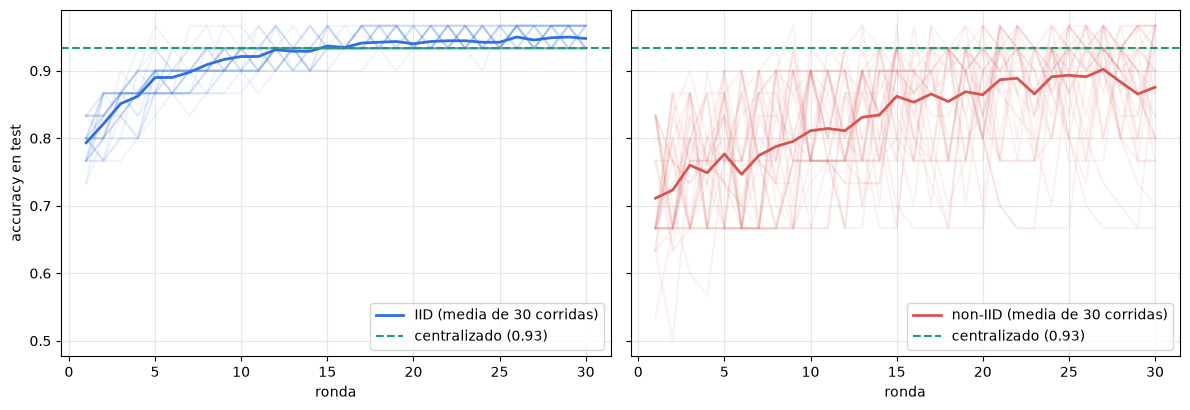

oscilación media ronda a ronda (rondas 6+): IID=0.013 | non-IID=0.073


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
x = np.arange(1, ROUNDS + 1)
for a, H, nombre, c in [(ax[0], H_iid, "IID", "#2F6FDE"), (ax[1], H_niid, "non-IID", "#D9534F")]:
    a.plot(x, H.T, color=c, alpha=.08)
    a.plot(x, H.mean(0), color=c, lw=2, label=f"{nombre} (media de {len(SEEDS)} corridas)")
    a.axhline(acc_central, ls="--", color="#1F9D6B", label=f"centralizado ({acc_central:.2f})")
    a.set_xlabel("ronda"); a.grid(alpha=.3); a.legend(loc="lower right")
ax[0].set_ylabel("accuracy en test")
plt.tight_layout(); plt.show()

osc = lambda H: np.abs(np.diff(H[:, 5:], axis=1)).mean()
print(f"oscilación media ronda a ronda (rondas 6+): IID={osc(H_iid):.3f} | non-IID={osc(H_niid):.3f}")

## 5. Privacidad diferencial (DP-FedAvg)

Federar **no es privado por sí solo**: los pesos que sube cada cliente filtran
información sobre sus datos. La defensa estándar es, en cada ronda:

1. **recortar** el update de cada cliente a norma L2 ≤ `S` (acota cuánto puede
   influir una sola persona), y
2. sumar **ruido gaussiano** al promedio, con desvío `sigma * S / m`.

Barro `sigma` (0 = solo recorte) sobre la partición IID y mido el costo.
Ojo: con `sigma > 0` y tan pocos clientes por ronda (m = 2) el ruido pesa
mucho; es una demostración del trade-off, no una garantía formal (ε, δ).

sin DP (IID)  : 0.948 ± 0.017
clip=1.0, sigma=0   : 0.948 ± 0.017
clip=1.0, sigma=0.5 : 0.939 ± 0.037
clip=1.0, sigma=1   : 0.893 ± 0.064
clip=1.0, sigma=2   : 0.782 ± 0.110
clip=1.0, sigma=4   : 0.650 ± 0.149
clip=1.0, sigma=8   : 0.549 ± 0.176


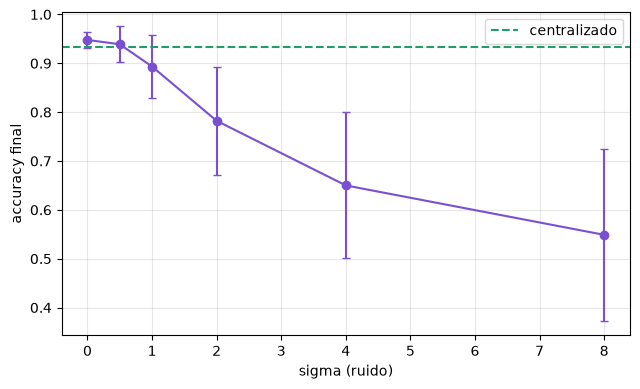

In [5]:
SIGMAS = [0, 0.5, 1, 2, 4, 8]
S = 1.0
dp = {}
for sg in SIGMAS:
    H = correr(partition_iid, clip=S, sigma=sg)
    dp[sg] = (H[:, -1].mean(), H[:, -1].std())

print(f"sin DP (IID)  : {H_iid[:, -1].mean():.3f} ± {H_iid[:, -1].std():.3f}")
for sg, (m, s) in dp.items():
    print(f"clip={S}, sigma={sg:<4}: {m:.3f} ± {s:.3f}")

plt.figure(figsize=(6.5, 4))
plt.errorbar(SIGMAS, [v[0] for v in dp.values()], [v[1] for v in dp.values()],
             fmt="-o", capsize=3, color="#7B4FD1")
plt.axhline(acc_central, ls="--", color="#1F9D6B", label="centralizado")
plt.xlabel("sigma (ruido)"); plt.ylabel("accuracy final"); plt.grid(alpha=.3)
plt.legend(); plt.tight_layout(); plt.show()

## Reflexión

**¿Cuánto se pierde al federar?** En IID, nada medible: 0.948 ± 0.017 contra
0.933 del centralizado. Que el federado salga *por encima* es ruido: el test
tiene 30 filas y una sola fila equivale a 0.033, así que la diferencia está
dentro de un error. Con non-IID (un cliente = una clase) la media baja a
0.876 y el desvío sube a 0.086, con corridas que llegan a 0.67. Hay un costo
real, pero no en el promedio sino en la **varianza**: depende de qué clientes
tocaron en las últimas rondas.

**Estabilidad.** La curva IID casi no se mueve de ronda a ronda (oscilación
0.013) y la non-IID oscila 0.073, unas 5 veces más. Con un cliente de una sola
clase, el entrenamiento local empuja el modelo hacia "todo es esa clase" y el
promedio de solo 2 clientes por ronda no alcanza a compensarlo. Es el *client
drift* de FedAvg: el modelo global queda sesgado hacia las clases de los
últimos clientes elegidos.

**Privacidad.** Recortar el update a norma 1 es gratis (sigma=0 da lo mismo
que sin DP). El costo aparece con el ruido: 0.939 con sigma=0.5, 0.893 con
sigma=1, 0.782 con sigma=2 y 0.549 con sigma=8. Acá el ruido pesa mucho porque
el desvío se divide por m=2 clientes por ronda; con miles de clientes el mismo
sigma sería mucho más barato. No calculé (ε, δ), así que esto muestra la
forma del trade-off pero no es una garantía formal.

**¿Orgánico o forzado?** Forzado. Iris es público y cabe en memoria; no hay
razón de privacidad, regulación ni latencia para no centralizarlo, y el RF
centralizado del Mini-TP 1 ya alcanza 0.90. Federarlo sirve para entender el
mecanismo. Tendría sentido orgánico si los datos fueran de sensores o
usuarios que no pueden salir de su origen; ahí el caso non-IID es el
realista, y es el que habría que vigilar (mejor muestreo de clientes,
menos épocas locales o un término de regularización tipo FedProx).